<a href="https://colab.research.google.com/github/Ritapaz/series_temporais/blob/main/ARIMA_SARIMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip -q install openpyxl statsmodels scikit-learn

import itertools
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from google.colab import files
from IPython.display import display
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["axes.grid"] = True

HORIZONTES = [1, 3, 6, 12]
PERIODO_SAZONAL = 12
MESES_TESTE = 24

In [ ]:

# Carregar a planilha
uploaded = files.upload()

nome_arquivo = next(iter(uploaded))

# Configurações
ABA_EXCEL = 0

COLUNA_DATA = None
COLUNA_CONSUMO = None

# True: transforma MWh em GWh
CONVERTER_PARA_GWH = True

df = pd.read_excel(
    nome_arquivo,
    sheet_name=ABA_EXCEL,
)

print("Colunas encontradas:")
print(df.columns.tolist())

# Identificação das colunas
if COLUNA_DATA is None:
    COLUNA_DATA = df.columns[0]

if COLUNA_CONSUMO is None:
    COLUNA_CONSUMO = df.columns[1]

df = df[[COLUNA_DATA, COLUNA_CONSUMO]].copy()

df.columns = ["Data", "Consumo"]

# Tratamento das datas
if pd.api.types.is_numeric_dtype(df["Data"]):
    df["Data"] = pd.to_datetime(
        df["Data"],
        unit="D",
        origin="1899-12-30",
        errors="coerce",
    )
else:
    df["Data"] = pd.to_datetime(
        df["Data"],
        dayfirst=True,
        errors="coerce",
    )

# Tratamento dos valores
df["Consumo"] = pd.to_numeric(
    df["Consumo"],
    errors="coerce",
)

# Eliminar linhas totalmente vazias
df = df.dropna(how="all")

# Verificar dados inválidos
if df[["Data", "Consumo"]].isna().any().any():
    raise ValueError(
        "Existem datas ou valores de consumo inválidos. "
        "Verifique a planilha original."
    )

# Padronização mensal
df["Data"] = df["Data"].dt.to_period("M").dt.to_timestamp()

if df["Data"].duplicated().any():
    raise ValueError("Existem meses duplicados na planilha.")

df = df.sort_values("Data").set_index("Data")

df = df.asfreq("MS")

if df["Consumo"].isna().any():
    raise ValueError(
        "Existem meses sem observação. "
        "Verifique a continuidade da série."
    )

if (df["Consumo"] <= 0).any():
    raise ValueError("O consumo deve apresentar valores positivos.")

# Conversão de unidades
if CONVERTER_PARA_GWH:
    df["Consumo"] = df["Consumo"] / 1000
    UNIDADE = "GWh"
else:
    UNIDADE = "MWh"

serie = df["Consumo"].astype(float)

print(f"Período inicial: {serie.index.min():%m/%Y}")
print(f"Período final: {serie.index.max():%m/%Y}")
print(f"Observações: {len(serie)}")
print(f"Unidade: {UNIDADE}")

display(df.head())
display(df.tail())

Saving Consumo de energia.xlsx to Consumo de energia (1).xlsx
Colunas encontradas:
['Data', 'Consumo MWh']
Período inicial: 01/2004
Período final: 07/2026
Observações: 271
Unidade: GWh


,Consumo
Data,
2004-01-01,26978.361463
2004-02-01,26508.269295
2004-03-01,27284.337172
2004-04-01,28046.181323
2004-05-01,27248.156753


,Consumo
Data,
2026-03-01,48937.203723
2026-04-01,49635.166888
2026-05-01,48034.965326
2026-06-01,46203.188624
2026-07-01,46840.979536


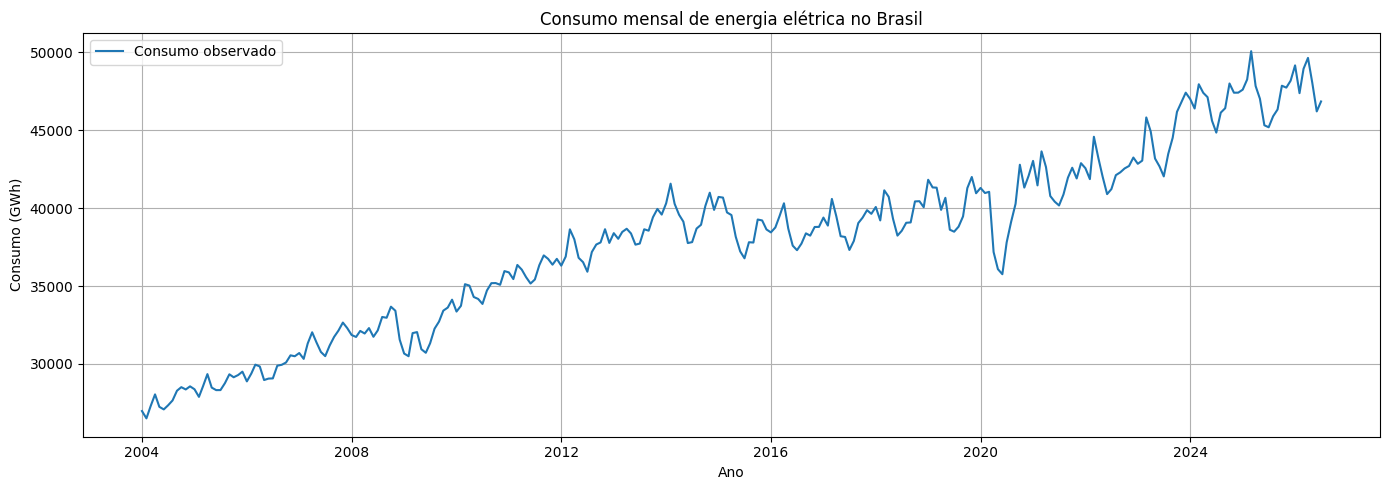

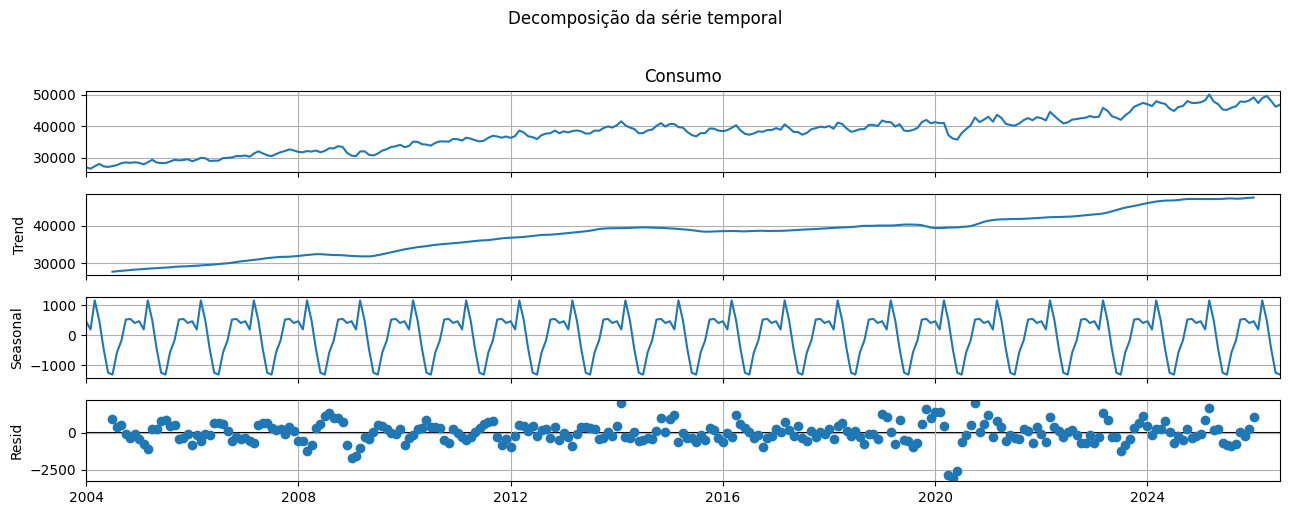

,Consumo
count,271.000000
mean,37860.553345
std,5680.950336
min,26508.269295
25%,33386.318623
50%,38544.210309
75%,41312.543191
max,50066.217296


In [ ]:

# Série histórica
plt.figure(figsize=(14, 5))

plt.plot(
    serie.index,
    serie,
    label="Consumo observado",
)

plt.title("Consumo mensal de energia elétrica no Brasil")
plt.xlabel("Ano")
plt.ylabel(f"Consumo ({UNIDADE})")
plt.legend()
plt.tight_layout()
plt.show()

# Decomposição sazonal
decomposicao = seasonal_decompose(
    serie,
    model="additive",
    period=12,
)

decomposicao.plot()
plt.suptitle(
    "Decomposição da série temporal",
    y=1.02,
)
plt.tight_layout()
plt.show()

# Estatísticas descritivas
display(serie.describe().to_frame("Consumo"))

TREINAMENTO
2004-01-01 00:00:00 até 2024-07-01 00:00:00
Observações: 247

TESTE
2024-08-01 00:00:00 até 2026-07-01 00:00:00
Observações: 24


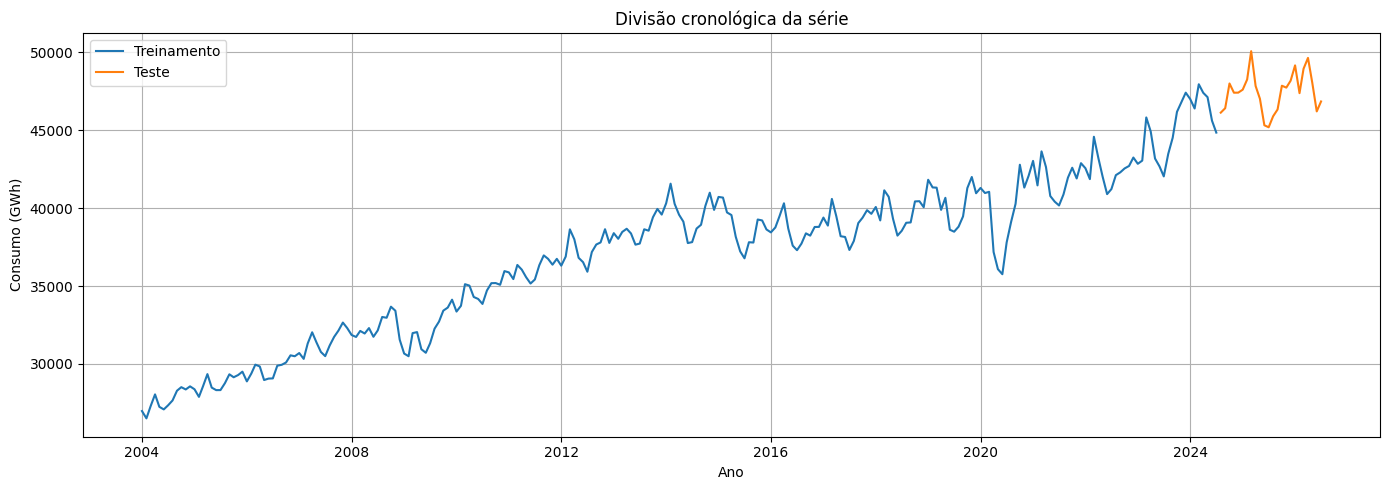

In [ ]:

treino = serie.iloc[:-MESES_TESTE].copy()
teste = serie.iloc[-MESES_TESTE:].copy()

print("TREINAMENTO")
print(treino.index.min(), "até", treino.index.max())
print("Observações:", len(treino))

print("\nTESTE")
print(teste.index.min(), "até", teste.index.max())
print("Observações:", len(teste))

plt.figure(figsize=(14, 5))

plt.plot(
    treino.index,
    treino,
    label="Treinamento",
)

plt.plot(
    teste.index,
    teste,
    label="Teste",
)

plt.title("Divisão cronológica da série")
plt.xlabel("Ano")
plt.ylabel(f"Consumo ({UNIDADE})")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

def teste_adf(dados, nome):
    resultado = adfuller(
        dados.dropna(),
        autolag="AIC",
    )

    print(f"\nTeste ADF: {nome}")
    print(f"Estatística ADF: {resultado[0]:.4f}")
    print(f"p-valor: {resultado[1]:.4f}")

    if resultado[1] < 0.05:
        print("Rejeita-se a hipótese de raiz unitária.")
    else:
        print("Não se rejeita a hipótese de raiz unitária.")


teste_adf(treino, "Série original")

teste_adf(
    treino.diff(),
    "Primeira diferença",
)

teste_adf(
    treino.diff(12),
    "Diferença sazonal",
)

teste_adf(
    treino.diff().diff(12),
    "Diferença regular e sazonal",
)


Teste ADF: Série original
Estatística ADF: -0.2160
p-valor: 0.9366
Não se rejeita a hipótese de raiz unitária.

Teste ADF: Primeira diferença
Estatística ADF: -4.3588
p-valor: 0.0004
Rejeita-se a hipótese de raiz unitária.

Teste ADF: Diferença sazonal
Estatística ADF: -2.7293
p-valor: 0.0691
Não se rejeita a hipótese de raiz unitária.

Teste ADF: Diferença regular e sazonal
Estatística ADF: -6.9874
p-valor: 0.0000
Rejeita-se a hipótese de raiz unitária.


In [ ]:
def ajustar_modelo(
    dados,
    ordem,
    ordem_sazonal=(0, 0, 0, 0),
):
    modelo = SARIMAX(
        dados,
        order=ordem,
        seasonal_order=ordem_sazonal,
        trend="n",
        enforce_stationarity=True,
        enforce_invertibility=True,
    )

    resultado = modelo.fit(
        disp=False,
        maxiter=150,
    )

    return resultado


def buscar_modelo(
    dados,
    tipo="ARIMA",
):
    candidatos = []

    if tipo == "ARIMA":
        ordens = itertools.product(
            range(3),
            range(2),
            range(3),
        )

        combinacoes = [
            (ordem, (0, 0, 0, 0))
            for ordem in ordens
        ]

    elif tipo == "SARIMA":
        ordens = itertools.product(
            range(2),
            range(2),
            range(2),
        )

        sazonais = list(
            itertools.product(
                range(2),
                range(2),
                range(2),
            )
        )

        combinacoes = [
            (ordem, sazonal + (12,))
            for ordem in ordens
            for sazonal in sazonais
        ]

    else:
        raise ValueError("Tipo deve ser ARIMA ou SARIMA.")

    print(f"\nBuscando modelos {tipo}...")

    for ordem, ordem_sazonal in combinacoes:
        try:
            resultado = ajustar_modelo(
                dados,
                ordem,
                ordem_sazonal,
            )

            convergiu = resultado.mle_retvals.get(
                "converged",
                False,
            )

            if convergiu and np.isfinite(resultado.aic):
                candidatos.append({
                    "Modelo": tipo,
                    "Ordem": ordem,
                    "Ordem sazonal": ordem_sazonal,
                    "AIC": resultado.aic,
                    "BIC": resultado.bic,
                })

        except (
            ValueError,
            np.linalg.LinAlgError,
        ):
            continue

    if not candidatos:
        raise RuntimeError(
            f"Nenhum modelo {tipo} convergiu."
        )

    ranking = pd.DataFrame(candidatos)

    ranking = ranking.sort_values(
        "AIC",
    ).reset_index(drop=True)

    print(f"Modelos convergentes: {len(ranking)}")

    display(ranking.head(10))

    return ranking


ranking_arima = buscar_modelo(
    treino,
    tipo="ARIMA",
)

ranking_sarima = buscar_modelo(
    treino,
    tipo="SARIMA",
)

# Seleção dos melhores modelos
melhor_arima = ranking_arima.iloc[0]
melhor_sarima = ranking_sarima.iloc[0]

ordem_arima = melhor_arima["Ordem"]

ordem_sarima = melhor_sarima["Ordem"]
sazonal_sarima = melhor_sarima["Ordem sazonal"]

# Fit the best models
modelo_arima = ajustar_modelo(treino, ordem_arima)
modelo_sarima = ajustar_modelo(treino, ordem_sarima, sazonal_sarima)

print("\nMELHORES ESPECIFICAÇÕES")

print("ARIMA:", ordem_arima)

print(
    "SARIMA:",
    ordem_sarima,
    sazonal_sarima,
)


Buscando modelos ARIMA...
Modelos convergentes: 18


,Modelo,Ordem,Ordem sazonal,AIC,BIC
0,ARIMA,"(0, 1, 0)","(0, 0, 0, 0)",4039.342212,4042.847544
1,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",4040.361892,4050.877887
2,ARIMA,"(2, 1, 1)","(0, 0, 0, 0)",4040.497944,4054.519270
3,ARIMA,"(1, 1, 2)","(0, 0, 0, 0)",4040.779282,4054.800608
4,ARIMA,"(1, 1, 0)","(0, 0, 0, 0)",4041.333879,4048.344543
5,ARIMA,"(0, 1, 1)","(0, 0, 0, 0)",4041.336069,4048.346732
6,ARIMA,"(2, 1, 2)","(0, 0, 0, 0)",4042.353840,4059.880497
7,ARIMA,"(0, 1, 2)","(0, 0, 0, 0)",4043.188980,4053.704974
8,ARIMA,"(2, 1, 0)","(0, 0, 0, 0)",4043.223311,4053.739306
9,ARIMA,"(1, 0, 0)","(0, 0, 0, 0)",4065.182276,4072.201053



Buscando modelos SARIMA...
Modelos convergentes: 64


,Modelo,Ordem,Ordem sazonal,AIC,BIC
0,SARIMA,"(0, 0, 1)","(1, 1, 1, 12)",2082.012094,2095.850436
1,SARIMA,"(1, 1, 1)","(1, 1, 1, 12)",3766.840050,3784.116656
2,SARIMA,"(0, 1, 1)","(1, 1, 1, 12)",3769.339480,3783.160765
3,SARIMA,"(0, 1, 0)","(1, 1, 1, 12)",3769.352332,3779.718295
4,SARIMA,"(1, 1, 0)","(1, 1, 1, 12)",3769.774274,3783.595559
5,SARIMA,"(1, 1, 1)","(0, 1, 1, 12)",3781.802331,3795.623616
6,SARIMA,"(0, 1, 1)","(0, 1, 1, 12)",3784.990602,3795.356566
7,SARIMA,"(0, 1, 0)","(0, 1, 1, 12)",3785.585613,3792.496255
8,SARIMA,"(1, 1, 0)","(0, 1, 1, 12)",3785.608116,3795.974080
9,SARIMA,"(1, 1, 1)","(1, 1, 0, 12)",3791.889477,3805.710761



MELHORES ESPECIFICAÇÕES
ARIMA: (0, 1, 0)
SARIMA: (0, 0, 1) (1, 1, 1, 12)



DIAGNÓSTICO: ARIMA


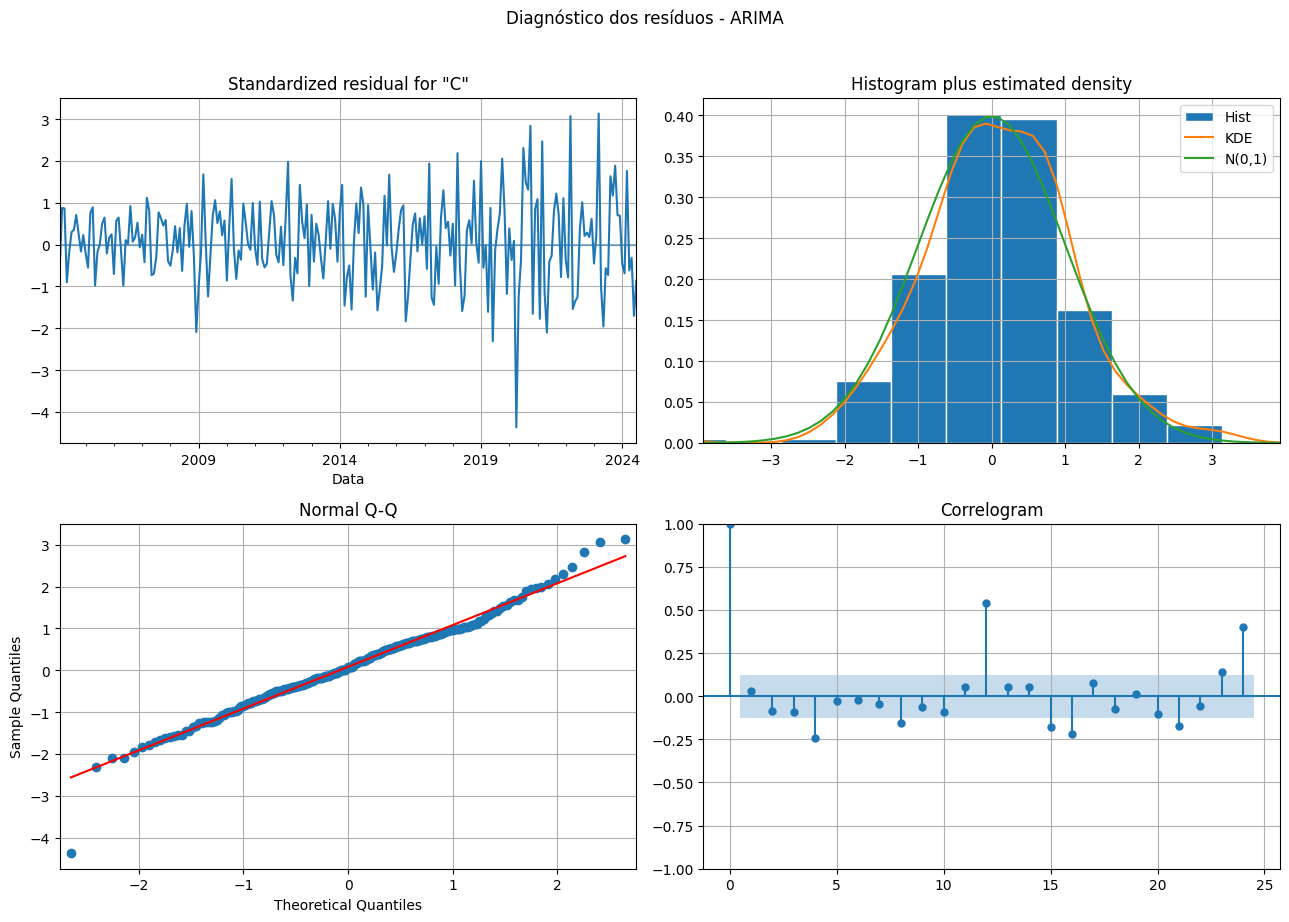

,lb_stat,lb_pvalue
12,100.121099,5.271767e-16
24,183.001953,1.954637e-26



DIAGNÓSTICO: SARIMA


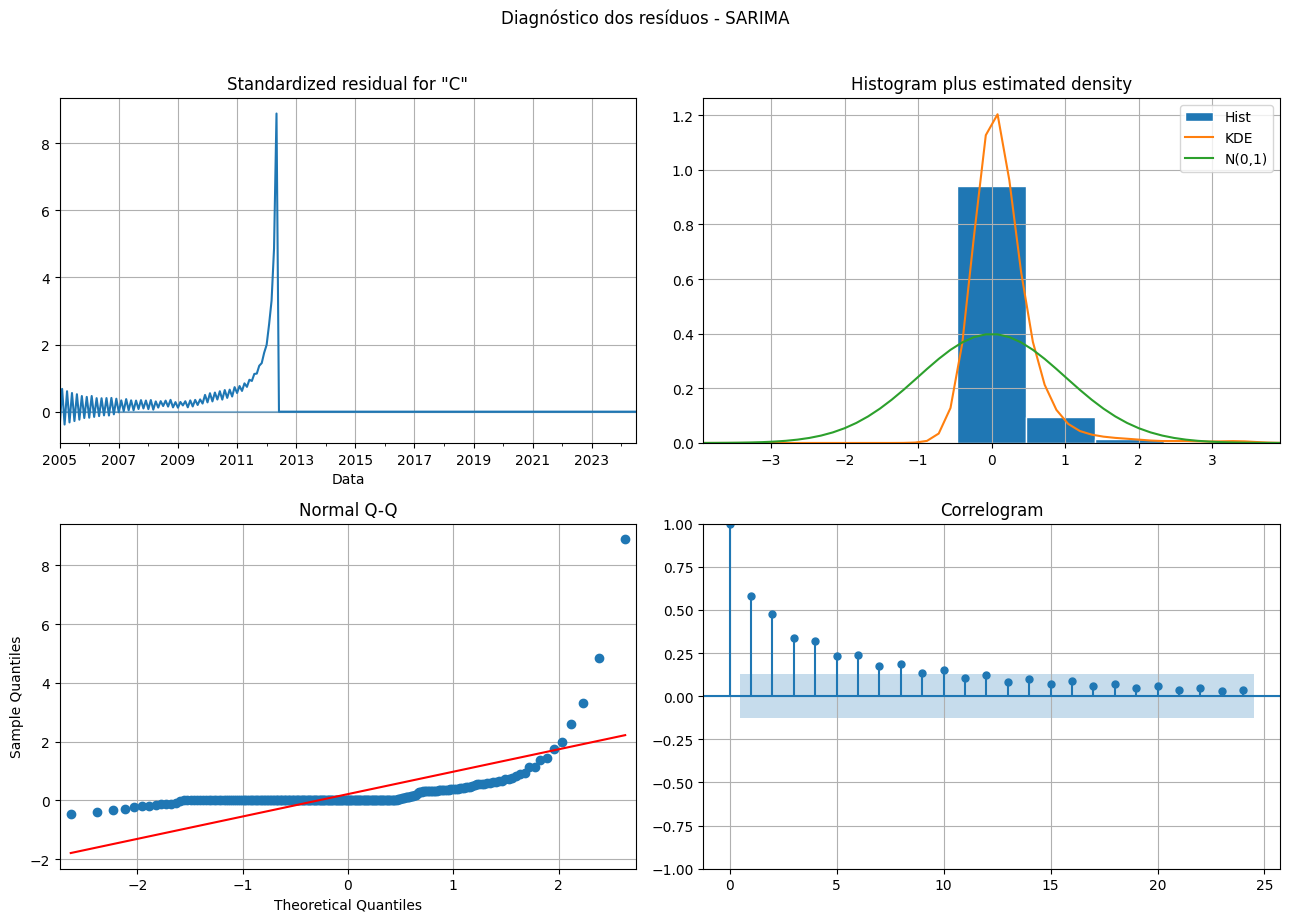

,lb_stat,lb_pvalue
12,2510.259344,0.0
24,4420.717010,0.0


In [ ]:
def diagnostico_residuos(resultado, nome):
    # Descartar observações iniciais de inicialização
    inicio = max(
        resultado.loglikelihood_burn,
        12,
    )

    residuos = resultado.resid.iloc[inicio:].dropna()

    print(f"\nDIAGNÓSTICO: {nome}")

    fig = resultado.plot_diagnostics(
        figsize=(13, 9),
        lags=24,
    )

    fig.suptitle(
        f"Diagnóstico dos resíduos - {nome}",
        y=1.02,
    )

    plt.tight_layout()
    plt.show()

    ljung_box = acorr_ljungbox(
        residuos,
        lags=[12, 24],
        return_df=True,
    )

    display(ljung_box)


diagnostico_residuos(
    modelo_arima,
    "ARIMA",
)

diagnostico_residuos(
    modelo_sarima,
    "SARIMA",
)

In [ ]:

def calcular_metricas(real, previsto):
    real = np.asarray(real, dtype=float)
    previsto = np.asarray(previsto, dtype=float)

    mae = mean_absolute_error(real, previsto)

    mse = mean_squared_error(real, previsto)

    rmse = np.sqrt(mse)

    # MAPE em percentual
    mape = np.mean(
        np.abs((real - previsto) / real)
    ) * 100

    # sMAPE em percentual
    denominador = np.abs(real) + np.abs(previsto)

    smape = np.mean(
        200 * np.abs(real - previsto) / denominador
    )

    r2 = (
        r2_score(real, previsto)
        if len(real) >= 2
        else np.nan
    )

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "sMAPE (%)": smape,
        "R2": r2,
    }

In [ ]:
CONFIGURACOES = {
    "ARIMA": {
        "ordem": ordem_arima,
        "sazonal": (0, 0, 0, 0),
    },
    "SARIMA": {
        "ordem": ordem_sarima,
        "sazonal": sazonal_sarima,
    },
}


def validacao_temporal(serie, meses_teste=24):
    registros = []

    inicio_teste = len(serie) - meses_teste

    for nome, config in CONFIGURACOES.items():

        print(f"\nValidando {nome}...")

        for origem in range(
            inicio_teste,
            len(serie),
        ):
            historico = serie.iloc[:origem]

            try:
                resultado = ajustar_modelo(
                    historico,
                    config["ordem"],
                    config["sazonal"],
                )

                passos = min(
                    max(HORIZONTES),
                    len(serie) - origem,
                )

                previsoes = resultado.get_forecast(
                    steps=passos,
                ).predicted_mean

                for horizonte in HORIZONTES:

                    posicao = origem + horizonte - 1

                    if posicao >= len(serie):
                        continue

                    valor_real = serie.iloc[posicao]

                    # Ensure the forecast index aligns or handle potential missing forecasts
                    if (horizonte - 1) < len(previsoes):
                        valor_previsto = previsoes.iloc[
                            horizonte - 1
                        ]
                        registros.append({
                            "Modelo": nome,
                            "Horizonte": horizonte,
                            "Data origem": historico.index[-1],
                            "Data prevista": serie.index[posicao],
                            "Real": valor_real,
                            "Previsto": valor_previsto,
                            "Erro": valor_real - valor_previsto,
                        })
                    else:
                        # If forecast is not available for this horizon, record NaN
                        registros.append({
                            "Modelo": nome,
                            "Horizonte": horizonte,
                            "Data origem": historico.index[-1],
                            "Data prevista": serie.index[posicao],
                            "Real": valor_real,
                            "Previsto": np.nan,
                            "Erro": np.nan,
                        })

            except (ValueError, np.linalg.LinAlgError) as e:
                print(f"Erro ao ajustar modelo {nome} para origem {historico.index[-1].strftime('%Y-%m-%d')}: {e}")
                # If an error occurs during model fitting, all subsequent forecasts from this origin are invalid.
                for horizonte in HORIZONTES:
                    posicao = origem + horizonte - 1
                    if posicao >= len(serie):
                        continue
                    valor_real = serie.iloc[posicao]
                    registros.append({
                        "Modelo": nome,
                        "Horizonte": horizonte,
                        "Data origem": historico.index[-1],
                        "Data prevista": serie.index[posicao],
                        "Real": valor_real,
                        "Previsto": np.nan,  # Assign NaN for problematic forecasts
                        "Erro": np.nan,
                    })
                # Continue to the next `origem` loop iteration.
                continue

        print(f"{nome}: validação concluída.")

    return pd.DataFrame(registros)


resultados_validacao = validacao_temporal(
    serie,
    meses_teste=MESES_TESTE,
)

display(resultados_validacao.head())


Validando ARIMA...
ARIMA: validação concluída.

Validando SARIMA...
Erro ao ajustar modelo SARIMA para origem 2024-11-01: LU decomposition error.
SARIMA: validação concluída.


,Modelo,Horizonte,Data origem,Data prevista,Real,Previsto,Erro
0,ARIMA,1,2024-07-01,2024-08-01,46122.399943,44842.586257,1279.813686
1,ARIMA,3,2024-07-01,2024-10-01,47994.158482,44842.586257,3151.572225
2,ARIMA,6,2024-07-01,2025-01-01,47597.235964,44842.586257,2754.649707
3,ARIMA,12,2024-07-01,2025-07-01,45184.502081,44842.586257,341.915824
4,ARIMA,1,2024-08-01,2024-09-01,46408.096769,46122.399943,285.696826


In [ ]:
metricas = (
    resultados_validacao.groupby(["Modelo", "Horizonte"])
    .apply(
        lambda x:
            # Create a temporary DataFrame for the group and drop rows where either 'Real' or 'Previsto' is NaN
            calcular_metricas(
                x.dropna(subset=["Real", "Previsto"])["Real"],
                x.dropna(subset=["Real", "Previsto"])["Previsto"],
            )
    )
    .unstack()
)

display(metricas)

Horizonte,1,3,6,12
Modelo,,,,
ARIMA,"{'MAE': 983.9197272916663, 'MSE': 1396950.1132...","{'MAE': 1626.6890760454532, 'MSE': 3920164.054...","{'MAE': 1985.8145961578932, 'MSE': 5338755.505...","{'MAE': 832.7648779230759, 'MSE': 1014866.6391..."
SARIMA,"{'MAE': 982590.9327245157, 'MSE': 753441589675...","{'MAE': 1076395.710622241, 'MSE': 825387832507...","{'MAE': 1319700.1718380684, 'MSE': 10681596155...","{'MAE': 1222176.8198588255, 'MSE': 89571012270..."


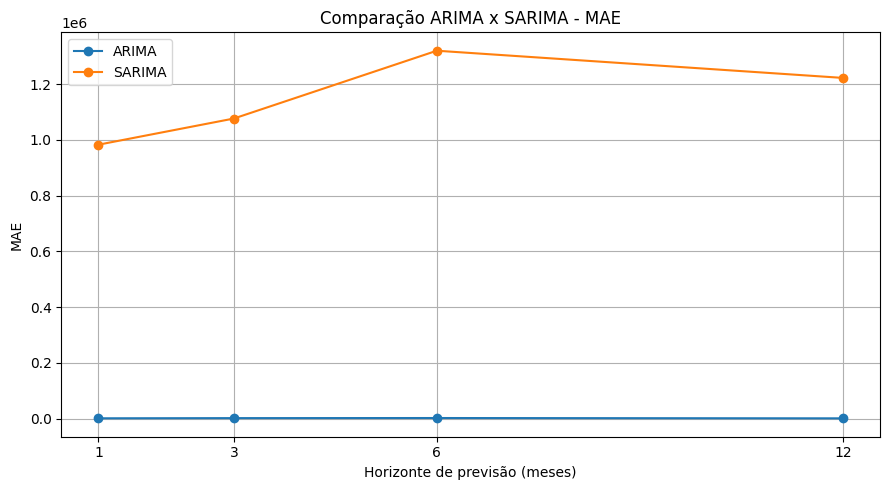

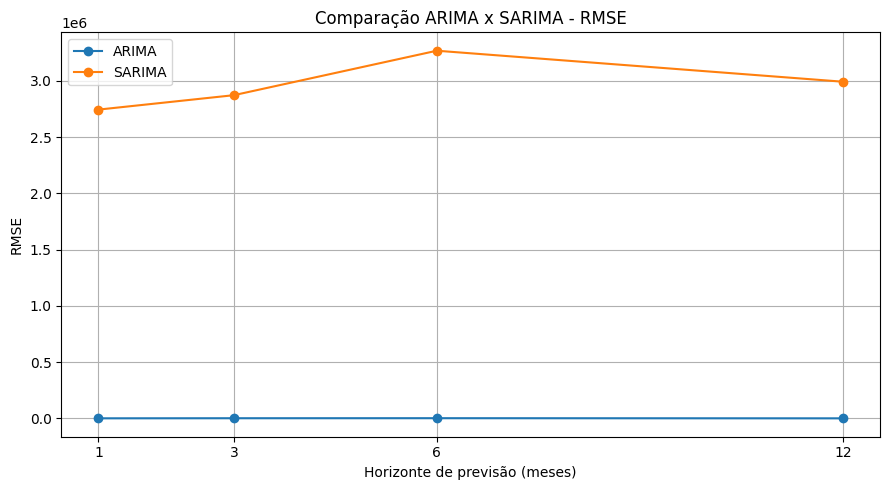

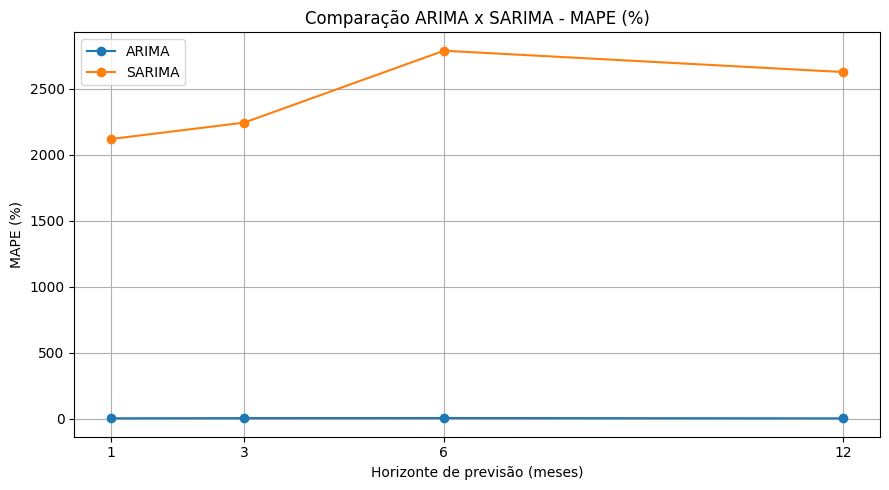

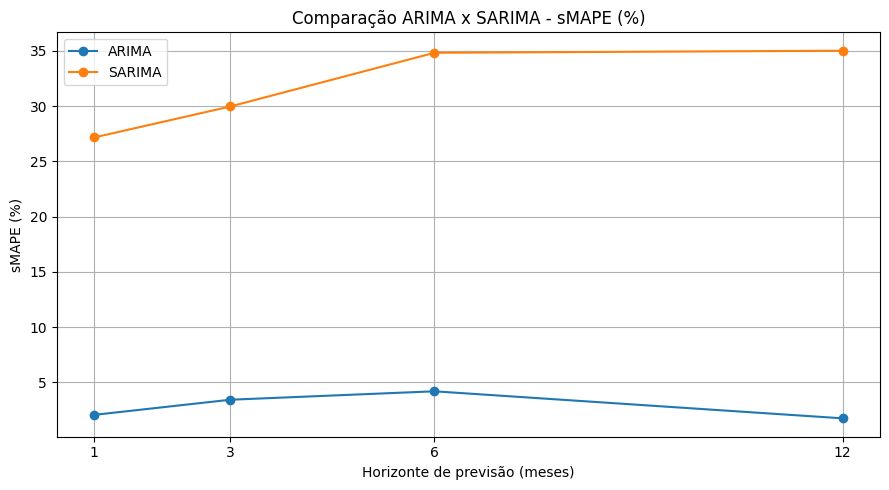

In [ ]:
for metrica in [
    "MAE",
    "RMSE",
    "MAPE (%)",
    "sMAPE (%)",
]:
    # Initialize a dictionary to hold data for the plot for the current metric
    plot_data = {}
    for model in metricas.index: # 'ARIMA', 'SARIMA'
        model_metrics = {}
        for horizon in metricas.columns: # 1, 3, 6, 12
            # Extract the specific metric value from the dictionary in the cell
            model_metrics[horizon] = metricas.loc[model, horizon][metrica]
        plot_data[model] = model_metrics

    # Create the DataFrame with horizons as index and models as columns
    tabela_grafico = pd.DataFrame(plot_data)
    tabela_grafico.index.name = 'Horizonte (meses)'

    tabela_grafico.plot(
        marker="o",
        figsize=(9, 5),
    )

    plt.title(
        f"Comparação ARIMA x SARIMA - {metrica}"
    )

    plt.xlabel("Horizonte de previsão (meses)")
    plt.ylabel(metrica)

    plt.xticks(HORIZONTES)
    plt.tight_layout()
    plt.show()

In [ ]:

modelo_final_arima = ajustar_modelo(
    serie,
    ordem_arima,
)

modelo_final_sarima = ajustar_modelo(
    serie,
    ordem_sarima,
    sazonal_sarima,
)

# Previsões para os próximos 12 meses
previsao_arima = modelo_final_arima.get_forecast(
    steps=12,
)

previsao_sarima = modelo_final_sarima.get_forecast(
    steps=12,
)

# Médias previstas
media_arima = previsao_arima.predicted_mean
media_sarima = previsao_sarima.predicted_mean

# Intervalos de confiança de 95%
ic_arima = previsao_arima.conf_int(
    alpha=0.05,
)

ic_sarima = previsao_sarima.conf_int(
    alpha=0.05,
)

# Construção da tabela
tabela_previsoes = pd.DataFrame({
    "ARIMA": media_arima,
    "SARIMA": media_sarima,
    "ARIMA LI 95%": ic_arima.iloc[:, 0],
    "ARIMA LS 95%": ic_arima.iloc[:, 1],
    "SARIMA LI 95%": ic_sarima.iloc[:, 0],
    "SARIMA LS 95%": ic_sarima.iloc[:, 1],
})

tabela_previsoes.index.name = "Data"

tabela_previsoes.insert(
    0,
    "Horizonte",
    range(1, 13),
)

print("PREVISÕES FUTURAS")

display(
    tabela_previsoes.round(2)
)

PREVISÕES FUTURAS


,Horizonte,ARIMA,SARIMA,ARIMA LI 95%,ARIMA LS 95%,SARIMA LI 95%,SARIMA LS 95%
Data,,,,,,,
2026-08-01,1,46840.98,47066.86,45048.12,48633.84,45190.73,48943.00
2026-09-01,2,46840.98,47172.48,44305.49,49376.47,44986.90,49358.07
2026-10-01,3,46840.98,48720.92,43735.66,49946.30,46535.34,50906.51
2026-11-01,4,46840.98,48629.45,43255.26,50426.70,46443.86,50815.03
2026-12-01,5,46840.98,49088.28,42832.02,50849.94,46902.78,51273.79
2027-01-01,6,46840.98,50007.48,42449.39,51232.57,47822.41,52192.56
2027-02-01,7,46840.98,48249.41,42097.52,51584.44,46064.35,50434.47
2027-03-01,8,46840.98,49824.41,41770.01,51911.95,47639.35,52009.47
2027-04-01,9,46840.98,50533.36,41462.40,52219.56,48348.31,52718.42


In [ ]:

previsoes_horizontes = tabela_previsoes[
    tabela_previsoes["Horizonte"].isin(
        HORIZONTES
    )
].copy()

display(
    previsoes_horizontes.round(2)
)

,Horizonte,ARIMA,SARIMA,ARIMA LI 95%,ARIMA LS 95%,SARIMA LI 95%,SARIMA LS 95%
Data,,,,,,,
2026-08-01,1,46840.98,47066.86,45048.12,48633.84,45190.73,48943.00
2026-10-01,3,46840.98,48720.92,43735.66,49946.30,46535.34,50906.51
2027-01-01,6,46840.98,50007.48,42449.39,51232.57,47822.41,52192.56
2027-07-01,12,46840.98,47684.70,40630.33,53051.63,45499.64,49869.75


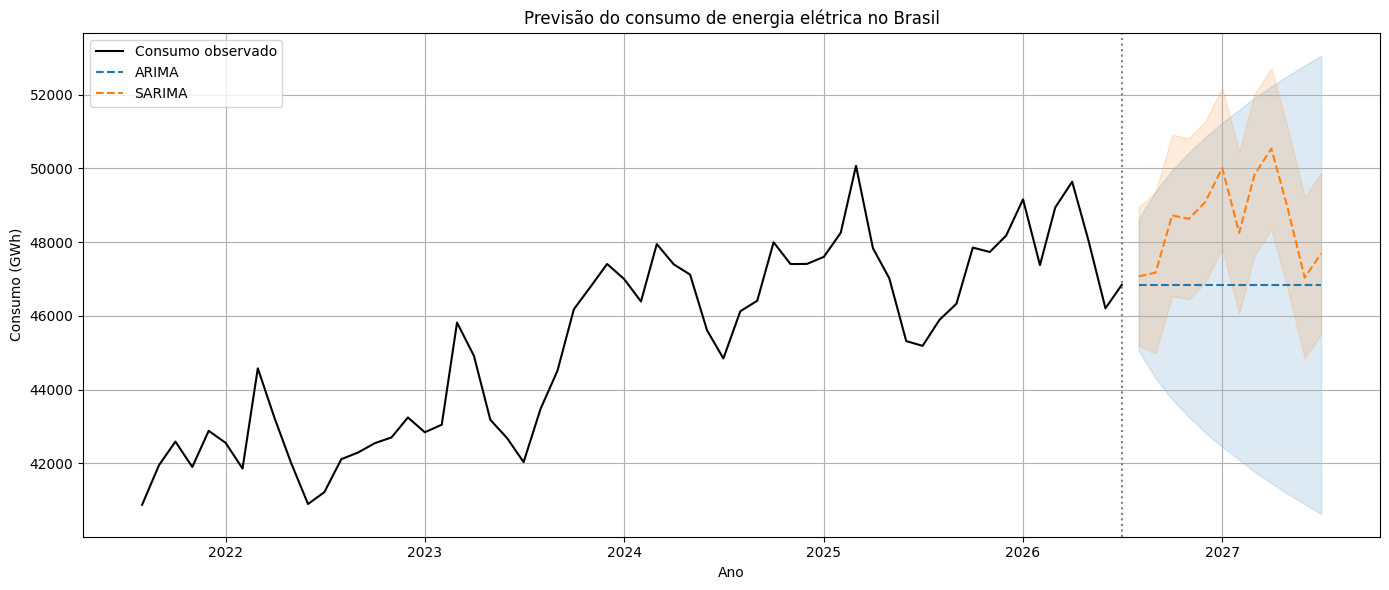

In [ ]:

# Exibir os últimos cinco anos da série histórica
historico_recente = serie.iloc[-60:]

plt.figure(figsize=(14, 6))

plt.plot(
    historico_recente.index,
    historico_recente,
    label="Consumo observado",
    color="black",
)

plt.plot(
    media_arima.index,
    media_arima,
    label="ARIMA",
    color="tab:blue",
    linestyle="--",
)

plt.plot(
    media_sarima.index,
    media_sarima,
    label="SARIMA",
    color="tab:orange",
    linestyle="--",
)

plt.fill_between(
    media_arima.index,
    ic_arima.iloc[:, 0],
    ic_arima.iloc[:, 1],
    color="tab:blue",
    alpha=0.15,
)

plt.fill_between(
    media_sarima.index,
    ic_sarima.iloc[:, 0],
    ic_sarima.iloc[:, 1],
    color="tab:orange",
    alpha=0.15,
)

plt.axvline(
    serie.index[-1],
    color="gray",
    linestyle=":",
)

plt.title(
    "Previsão do consumo de energia elétrica no Brasil"
)

plt.xlabel("Ano")
plt.ylabel(f"Consumo ({UNIDADE})")

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

registros_naive = []

inicio_teste = len(serie) - MESES_TESTE

for origem in range(
    inicio_teste,
    len(serie),
):
    historico = serie.iloc[:origem]

    for horizonte in HORIZONTES:

        posicao = origem + horizonte - 1

        if posicao >= len(serie):
            continue

        # Mesmo mês do ano anterior
        posicao_sazonal = posicao - 12

        valor_previsto = serie.iloc[posicao_sazonal]

        valor_real = serie.iloc[posicao]

        registros_naive.append({
            "Modelo": "Sazonal ingênuo",
            "Horizonte": horizonte,
            "Data origem": historico.index[-1],
            "Data prevista": serie.index[posicao],
            "Real": valor_real,
            "Previsto": valor_previsto,
            "Erro": valor_real - valor_previsto,
        })

resultados_naive = pd.DataFrame(
    registros_naive
)

# Adicionar à validação
resultados_validacao = pd.concat(
    [
        resultados_validacao,
        resultados_naive,
    ],
    ignore_index=True,
)

# Recalcular as métricas
metricas_comparativas = []

for (modelo, horizonte), grupo in (
    resultados_validacao.groupby(
        ["Modelo", "Horizonte"]
    )
):
    # Filtrar NaN antes de calcular as métricas
    grupo_limpo = grupo.dropna(subset=["Real", "Previsto"])

    if not grupo_limpo.empty: # Apenas calcule se houver dados válidos
        metricas = calcular_metricas(
            grupo_limpo["Real"],
            grupo_limpo["Previsto"],
        )

        metricas_comparativas.append({
            "Modelo": modelo,
            "Horizonte": horizonte,
            "N previsões": len(grupo_limpo),
            **metricas,
        })

metricas_comparativas = pd.DataFrame(
    metricas_comparativas
)

display(
    metricas_comparativas.round(4)
)

,Modelo,Horizonte,N previsões,MAE,MSE,RMSE,MAPE (%),sMAPE (%),R2
0,ARIMA,1,24,9.839197e+02,1.396950e+06,1.181926e+03,2.0682,2.0656,1.015000e-01
1,ARIMA,3,22,1.626689e+03,3.920164e+06,1.979940e+03,3.4467,3.4349,-1.520300e+00
2,ARIMA,6,19,1.985815e+03,5.338756e+06,2.310575e+03,4.1736,4.1972,-1.985100e+00
3,ARIMA,12,13,8.327649e+02,1.014867e+06,1.007406e+03,1.7354,1.7505,3.931000e-01
4,SARIMA,1,23,9.825909e+05,7.534416e+12,2.744889e+06,2119.1132,27.1641,-4.644568e+06
5,SARIMA,3,21,1.076396e+06,8.253878e+12,2.872956e+06,2243.4052,29.9654,-5.141486e+06
6,SARIMA,6,18,1.319700e+06,1.068160e+13,3.268271e+06,2788.4540,34.8232,-5.708540e+06
7,SARIMA,12,12,1.222177e+06,8.957101e+12,2.992842e+06,2626.7462,35.0100,-4.958645e+06
8,Sazonal ingênuo,1,24,9.672781e+02,1.504028e+06,1.226388e+03,2.0250,2.0545,3.260000e-02
9,Sazonal ingênuo,3,22,8.486153e+02,1.158511e+06,1.076341e+03,1.7623,1.7829,2.552000e-01


In [ ]:

# ============================================================
# EXPORTAÇÃO DOS RESULTADOS ARIMA/SARIMA PARA EXCEL
# ============================================================

import pandas as pd
from google.colab import files

# Nome do arquivo de saída
nome_arquivo = "Resultados_ARIMA_SARIMA_Energia.xlsx"

# ------------------------------------------------------------
# 1. Série histórica
# ------------------------------------------------------------

historico_excel = serie.reset_index()
historico_excel.columns = ["Data", f"Consumo ({UNIDADE})"]

# ------------------------------------------------------------
# 2. Parâmetros dos modelos
# ------------------------------------------------------------

parametros_excel = pd.DataFrame({
    "Modelo": ["ARIMA", "SARIMA"],
    "Ordem (p,d,q)": [
        str(ordem_arima),
        str(ordem_sarima),
    ],
    "Ordem sazonal (P,D,Q,s)": [
        "Não se aplica",
        str(sazonal_sarima),
    ],
    "AIC": [
        modelo_arima.aic,
        modelo_sarima.aic,
    ],
    "BIC": [
        modelo_arima.bic,
        modelo_sarima.bic,
    ],
})

# ------------------------------------------------------------
# 3. Métricas de avaliação
# ------------------------------------------------------------

metricas_excel = metricas_comparativas.copy()

# ------------------------------------------------------------
# 4. Resultados da validação temporal
# ------------------------------------------------------------

validacao_excel = resultados_validacao.copy()

validacao_excel = validacao_excel.sort_values(
    ["Modelo", "Horizonte", "Data prevista"]
)

# ------------------------------------------------------------
# 5. Previsões futuras dos 12 meses
# ------------------------------------------------------------

previsoes_excel = tabela_previsoes.reset_index()

# ------------------------------------------------------------
# 6. Previsões para os horizontes específicos
# ------------------------------------------------------------

horizontes_excel = previsoes_horizontes.reset_index()

# ------------------------------------------------------------
# 7. Erros de previsão por horizonte
# ------------------------------------------------------------

erros_excel = resultados_validacao[
    [
        "Modelo",
        "Horizonte",
        "Data origem",
        "Data prevista",
        "Real",
        "Previsto",
        "Erro",
    ]
].copy()

erros_excel["Erro absoluto"] = (
    erros_excel["Erro"].abs()
)

erros_excel["Erro percentual (%)"] = (
    erros_excel["Erro absoluto"]
    / erros_excel["Real"].abs()
) * 100

# ------------------------------------------------------------
# 8. Exportação para o Excel
# ------------------------------------------------------------

with pd.ExcelWriter(
    nome_arquivo,
    engine="openpyxl",
    datetime_format="DD/MM/YYYY",
    date_format="DD/MM/YYYY",
) as writer:

    historico_excel.to_excel(
        writer,
        sheet_name="Serie Historica",
        index=False,
    )

    parametros_excel.to_excel(
        writer,
        sheet_name="Parametros",
        index=False,
    )

    metricas_excel.to_excel(
        writer,
        sheet_name="Metricas",
        index=False,
    )

    validacao_excel.to_excel(
        writer,
        sheet_name="Validacao Temporal",
        index=False,
    )

    previsoes_excel.to_excel(
        writer,
        sheet_name="Previsoes 12 Meses",
        index=False,
    )

    horizontes_excel.to_excel(
        writer,
        sheet_name="Horizontes 1 3 6 12",
        index=False,
    )

    erros_excel.to_excel(
        writer,
        sheet_name="Erros de Previsao",
        index=False,
    )

    # --------------------------------------------------------
    # 9. Formatação automática das planilhas
    # --------------------------------------------------------

    workbook = writer.book

    from openpyxl.styles import (
        Alignment,
        Font,
        PatternFill,
    )

    from openpyxl.utils import get_column_letter

    for worksheet in workbook.worksheets:

        # Cabeçalho
        for cell in worksheet[1]:

            cell.font = Font(
                bold=True,
                color="FFFFFF",
            )

            cell.fill = PatternFill(
                start_color="1F4E78",
                end_color="1F4E78",
                fill_type="solid",
            )

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
            )

        # Congelar cabeçalho
        worksheet.freeze_panes = "A2"

        # Ativar filtros
        worksheet.auto_filter.ref = worksheet.dimensions

        # Ajustar largura das colunas
        for column in worksheet.columns:

            column_letter = get_column_letter(
                column[0].column
            )

            max_length = max(
                len(str(cell.value))
                if cell.value is not None
                else 0
                for cell in column
            )

            worksheet.column_dimensions[
                column_letter
            ].width = min(max_length + 3, 35)

        # Formatação numérica
        for row in worksheet.iter_rows(min_row=2):

            for cell in row:

                if isinstance(cell.value, float):
                    cell.number_format = "#,##0.0000"

# ------------------------------------------------------------
# 10. Download
# ------------------------------------------------------------

print("Arquivo Excel gerado com sucesso!")
print(f"Nome: {nome_arquivo}")

files.download(nome_arquivo)

Arquivo Excel gerado com sucesso!
Nome: Resultados_ARIMA_SARIMA_Energia.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>